In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split

from sklearn.cluster import KMeans

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score
)

from imblearn.over_sampling import SMOTE

In [3]:
X = pd.read_csv(
    "data/secom.data",
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    "data/secom_labels.data",
    sep=r"\s+",
    header=None
)

# First column contains labels
y = labels[0]


## Data Understanding

In [4]:
print("Dataset Shape:")
print("Samples:", X.shape[0])
print("Features:", X.shape[1])

print("\nTarget Labels Distribution:")
print(y.value_counts())

Dataset Shape:
Samples: 1567
Features: 590

Target Labels Distribution:
0
-1    1463
 1     104
Name: count, dtype: int64


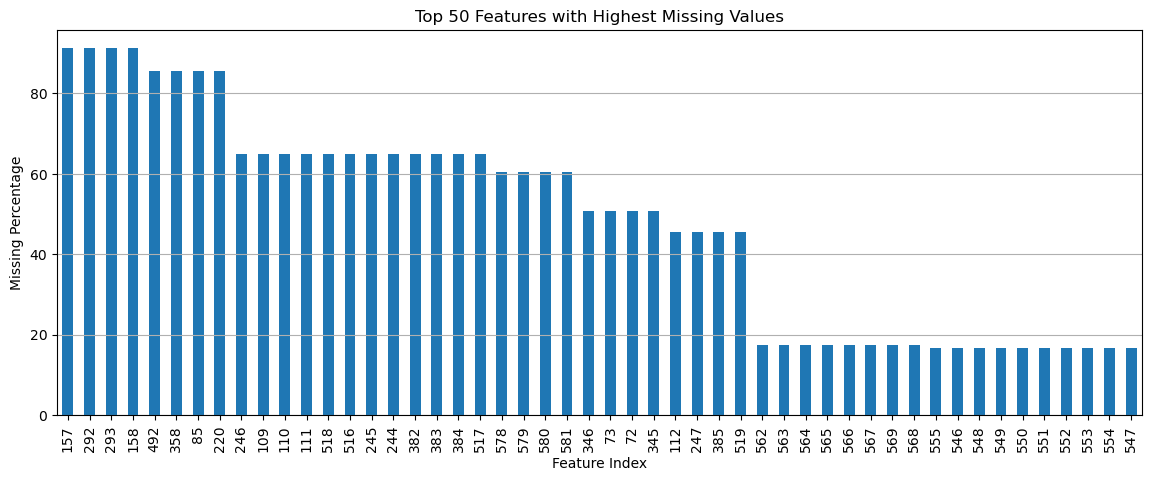

Features with more than 50% missing values:
28


In [5]:
# Percentage of missing values per feature
missing_percentage = X.isnull().mean() * 100

# Top 50 features with highest missing values
top_missing = missing_percentage.sort_values(ascending=False).head(50)

plt.figure(figsize=(14,5))

top_missing.plot(kind='bar')

plt.title("Top 50 Features with Highest Missing Values")
plt.xlabel("Feature Index")
plt.ylabel("Missing Percentage")

plt.grid(axis='y')
plt.show()

print("Features with more than 50% missing values:")
print((missing_percentage > 50).sum())

In [6]:
threshold = 0.5
removed_features = (X.isnull().mean() >= threshold).sum()
print("\nNumber of features removed:", removed_features)
X = X.loc[:, X.isnull().mean() < threshold]
print("Shape after removing high missing features:", X.shape)


Number of features removed: 28
Shape after removing high missing features: (1567, 562)


In [7]:
print("\nMissing values before imputation:")
print(X.isnull().sum().sum())


Missing values before imputation:
11683


In [8]:
imputation = SimpleImputer(strategy='median')
X_imputed = imputation.fit_transform(X)
print("\nShape after imputation:", X_imputed.shape)
X_imputed_df = pd.DataFrame(X_imputed)
print("Remaining missing values after median imputation:")
print(X_imputed_df.isnull().sum().sum())


Shape after imputation: (1567, 562)
Remaining missing values after median imputation:
0



Summary of feature variance:
count    5.620000e+02
mean     1.604012e+05
std      2.045890e+06
min      0.000000e+00
25%      8.774937e-06
50%      2.727999e-02
75%      3.842088e+01
max      4.290600e+07
dtype: float64


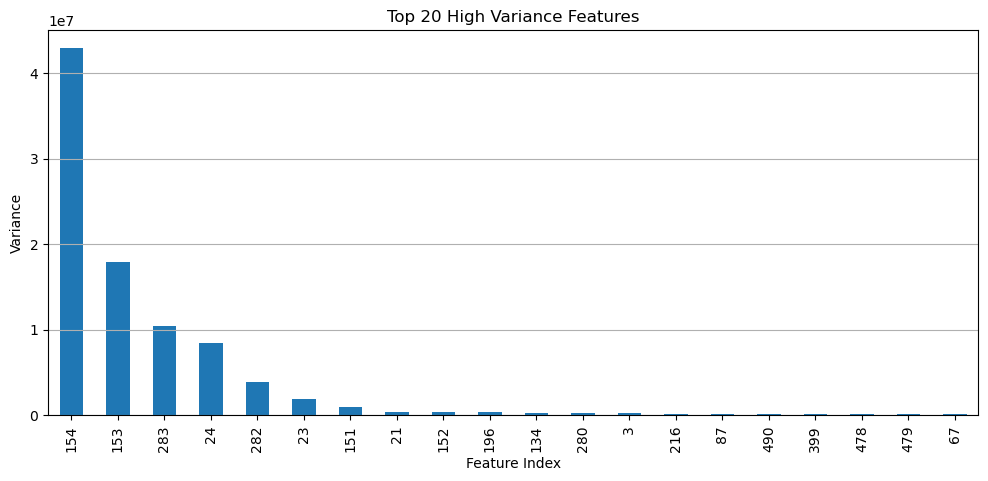

In [9]:
#Variance analysis
variance = X_imputed_df.var()

print("\nSummary of feature variance:")
print(variance.describe())

# Top 20 highest variance features
top_variance = variance.sort_values(ascending=False).head(20)
plt.figure(figsize=(12,5))
top_variance.plot(kind='bar')
plt.title("Top 20 High Variance Features")
plt.xlabel("Feature Index")
plt.ylabel("Variance")
plt.grid(axis='y')
plt.show()

In [10]:
# Count zero variance features
zero_variance_count = (variance == 0).sum()
print("Number of zero variance features removed:",
      zero_variance_count)

Number of zero variance features removed: 116


In [11]:
# Remove zero variance features
X_final = X_imputed_df.loc[:, variance > 0]
print("Final dataset shape after variance filtering:",
      X_final.shape)

Final dataset shape after variance filtering: (1567, 446)


In [12]:
# Before scaling
print("BEFORE SCALING (first 5 features):")
display(X_final.iloc[:, :5].describe().round(2))

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)

# After scaling (convert to DataFrame for inspection)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_final.columns)

print("\nAFTER SCALING (first 5 features):")
display(X_scaled_df.iloc[:, :5].describe().round(2))

print("\nFinal dataset:", X_scaled_df.shape)

BEFORE SCALING (first 5 features):


,0,1,2,3,4
count,1567.00,1567.00,1567.00,1567.00,1567.00
mean,3014.44,2495.87,2200.55,1395.38,4.17
std,73.48,80.23,29.38,439.84,56.10
min,2743.24,2158.75,2060.66,0.00,0.68
25%,2966.66,2452.89,2181.10,1083.89,1.02
50%,3011.49,2499.40,2201.07,1285.21,1.32
75%,3056.54,2538.74,2218.06,1590.17,1.52
max,3356.35,2846.44,2315.27,3715.04,1114.54



AFTER SCALING (first 5 features):


,0,1,2,3,4
count,1567.00,1567.00,1567.00,1567.00,1567.00
mean,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-3.69,-4.20,-4.76,-3.17,-0.06
25%,-0.65,-0.54,-0.66,-0.71,-0.06
50%,-0.04,0.04,0.02,-0.25,-0.05
75%,0.57,0.53,0.60,0.44,-0.05
max,4.65,4.37,3.91,5.28,19.80



Final dataset: (1567, 446)


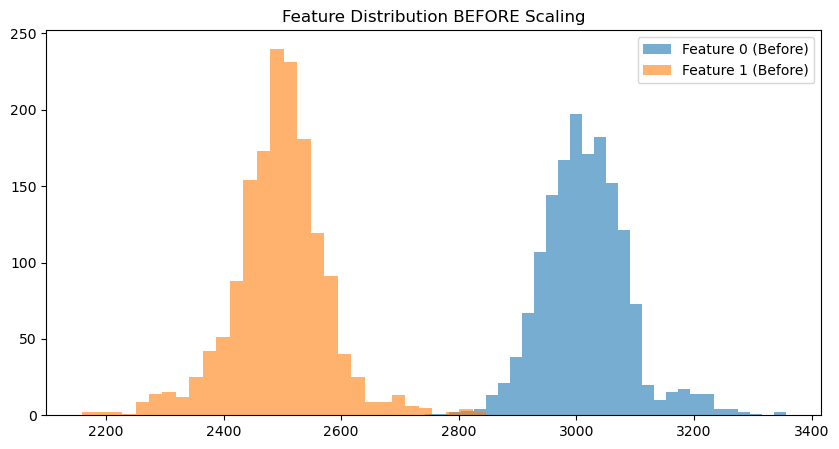

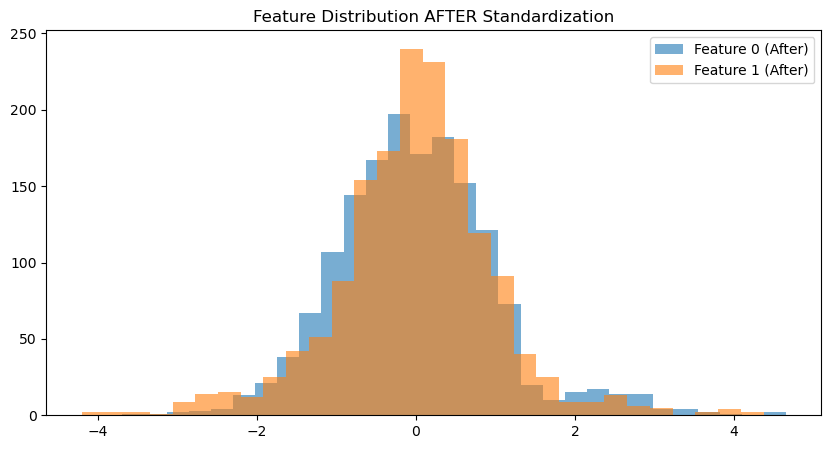

In [13]:
# BEFORE SCALING
plt.figure(figsize=(10,5))

plt.hist(X_final.iloc[:, 0], bins=30, alpha=0.6, label="Feature 0 (Before)")
plt.hist(X_final.iloc[:, 1], bins=30, alpha=0.6, label="Feature 1 (Before)")

plt.title("Feature Distribution BEFORE Scaling")
plt.legend()
plt.show()

# AFTER SCALING
plt.figure(figsize=(10,5))

plt.hist(X_scaled_df.iloc[:, 0], bins=30, alpha=0.6, label="Feature 0 (After)")
plt.hist(X_scaled_df.iloc[:, 1], bins=30, alpha=0.6, label="Feature 1 (After)")

plt.title("Feature Distribution AFTER Standardization")
plt.legend()
plt.show()

## EDA

In [14]:
X_df = pd.DataFrame(X_scaled, columns=X_final.columns)

In [15]:
X_df.describe().round(2)

,0,1,2,3,4,6,7,8,9,10,...,552,553,554,555,556,557,558,559,560,561
count,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,...,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00,1567.00
mean,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,...,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.69,-4.20,-4.76,-3.17,-0.06,-3.06,-13.64,-3.68,-3.48,-3.77,...,-0.29,-0.97,-6.55,-0.54,-0.58,-0.52,-3.11,-1.51,-1.49,-1.06
25%,-0.65,-0.54,-0.66,-0.71,-0.06,-0.51,-0.08,-0.70,-0.66,-0.62,...,-0.25,-0.41,-0.65,-0.22,-0.20,-0.21,-0.65,-0.67,-0.69,-0.59
50%,-0.04,0.04,0.02,-0.25,-0.05,0.06,0.06,-0.02,-0.03,0.03,...,-0.23,-0.23,0.03,-0.09,-0.07,-0.09,-0.08,-0.19,-0.24,-0.30
75%,0.57,0.53,0.60,0.44,-0.05,0.55,0.22,0.73,0.61,0.62,...,-0.22,0.04,0.66,0.07,0.07,0.06,0.50,0.43,0.39,0.16
max,4.65,4.37,3.91,5.28,19.80,4.53,0.76,2.62,5.02,5.69,...,5.02,6.44,2.85,26.87,27.07,26.91,6.59,7.21,8.14,6.80


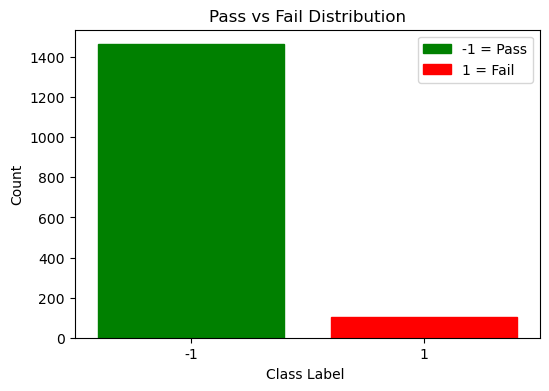

In [16]:
plt.figure(figsize=(6,4))

ax = sns.countplot(x=y)

ax.patches[0].set_color("green")  # -1 = Pass
ax.patches[1].set_color("red")    # 1 = Fail

plt.title("Pass vs Fail Distribution")
plt.xlabel("Class Label ")
plt.ylabel("Count")

pass_patch = mpatches.Patch(color="green", label='-1 = Pass')
fail_patch = mpatches.Patch(color="red", label='1 = Fail')

plt.legend(handles=[pass_patch, fail_patch])

plt.show()

In [17]:
print("Class distribution:")
print(y.value_counts())

fail_rate = (y.value_counts(normalize=True) * 100)

print("\nClass percentage distribution:")
print(fail_rate.round(2))

Class distribution:
0
-1    1463
 1     104
Name: count, dtype: int64

Class percentage distribution:
0
-1    93.36
 1     6.64
Name: proportion, dtype: float64


In [18]:
variance = X_df.var().sort_values(ascending=False)

print("Top 100 high variance features:")
display(variance.head(100))

Top 100 high variance features:


108    1.000639
237    1.000639
367    1.000639
365    1.000639
98     1.000639
         ...   
323    1.000639
390    1.000639
401    1.000639
549    1.000639
161    1.000639
Length: 100, dtype: float64

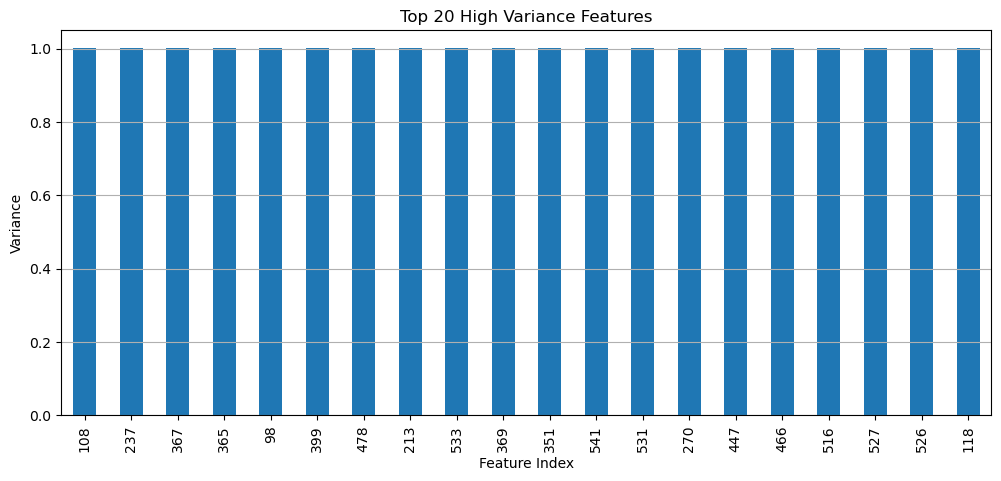

In [19]:
# Top 20 high variance features
top_variance = variance.head(20)

plt.figure(figsize=(12,5))

top_variance.plot(kind='bar')

plt.title("Top 20 High Variance Features")
plt.xlabel("Feature Index")
plt.ylabel("Variance")

plt.grid(axis='y')
plt.show()


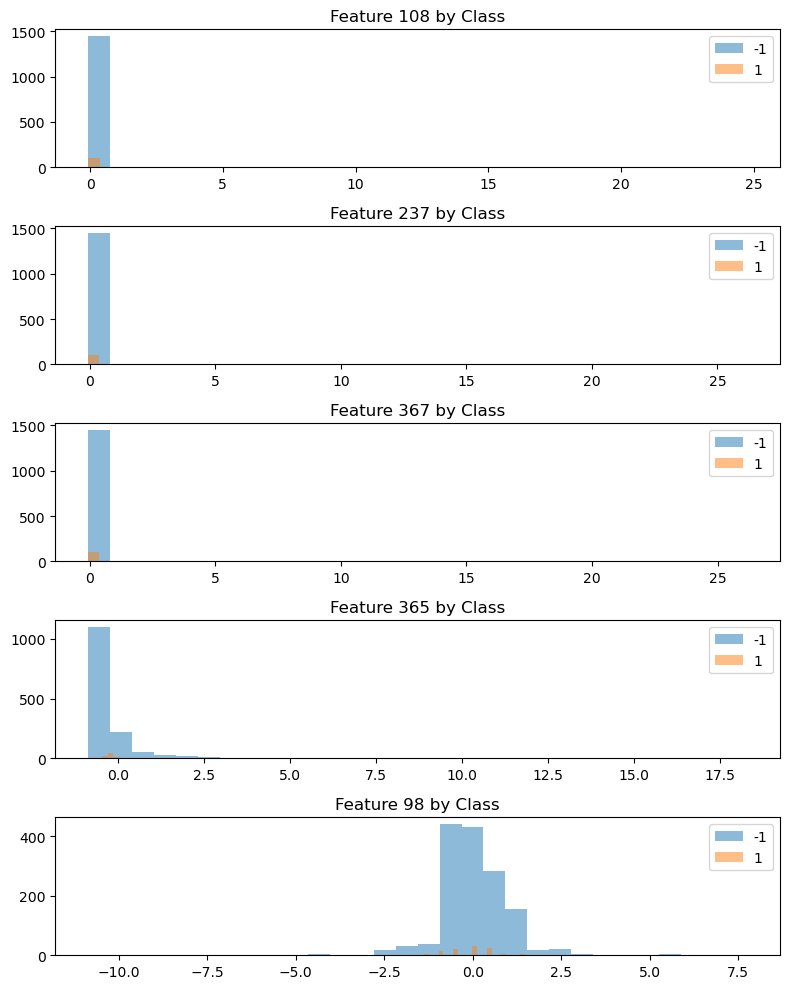

In [22]:
top_features = variance.head(5).index

fig, axes = plt.subplots(5, 1, figsize=(8,10))

for i, feat in enumerate(top_features):

    for label, grp in X_df.groupby(y):

        axes[i].hist(
            grp[feat],
            alpha=0.5,
            bins=30,
            label=label
        )

    axes[i].set_title(f"Feature {feat} by Class")
    axes[i].legend()

plt.tight_layout()
plt.show()

#The top 5 high-variance features were plotted by class label. 
#Several features show a visible distributional shift between pass and fail units, 
#suggesting discriminative signal exists despite the severe class imbalance

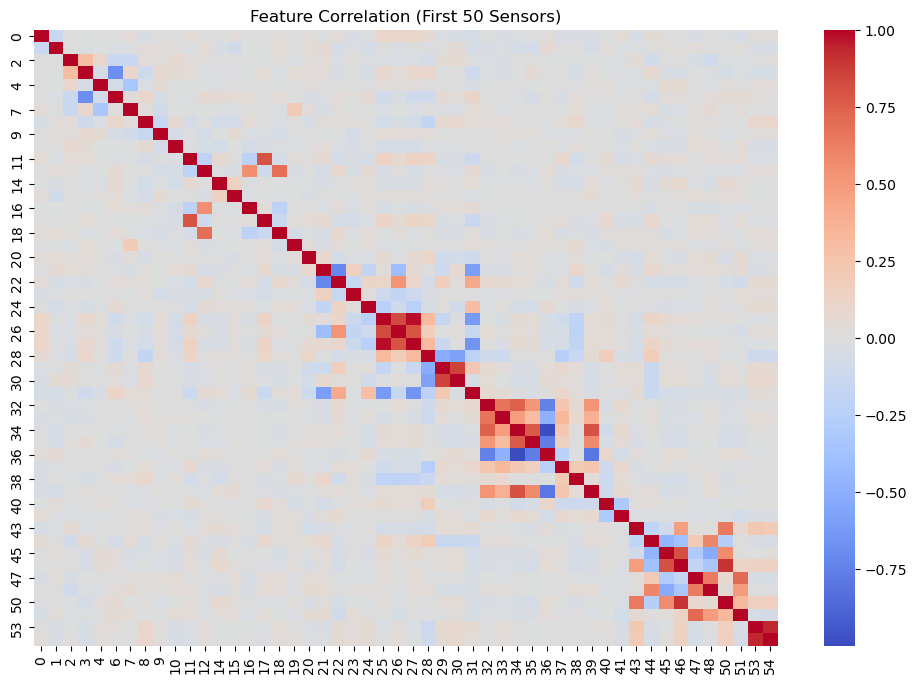

In [20]:
plt.figure(figsize=(12,8))

corr = X_df.iloc[:, :50].corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0
)

plt.title("Feature Correlation (First 50 Sensors)")
plt.show()

## Outlier

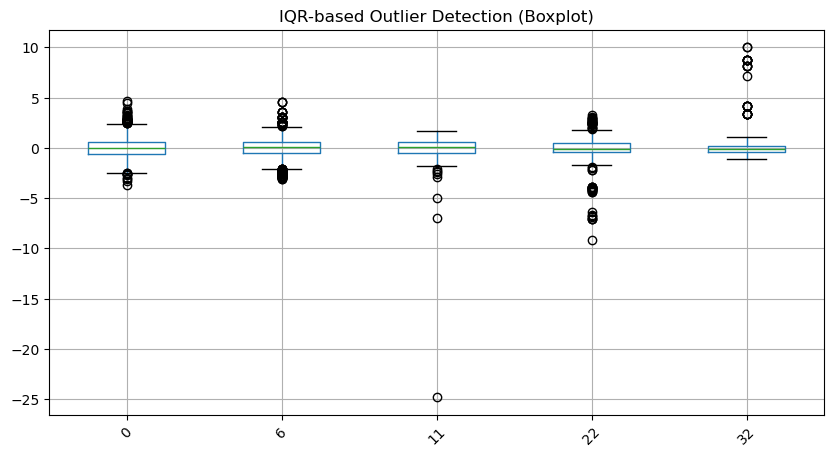

Total IQR Outliers: 26764


In [20]:
X_df = pd.DataFrame(X_scaled, columns=X_final.columns)

# IQR calculation
Q1 = X_df.quantile(0.25)
Q3 = X_df.quantile(0.75)
IQR = Q3 - Q1

iqr_outliers = ((X_df < (Q1 - 1.5 * IQR)) | (X_df > (Q3 + 1.5 * IQR)))

iqr_count = iqr_outliers.sum().sum()

# Boxplot (Random sample features)
sample_cols = X_df.iloc[:, [0, 5, 10, 20, 30]]

plt.figure(figsize=(10,5))
sample_cols.boxplot()

plt.title("IQR-based Outlier Detection (Boxplot)")
plt.xticks(rotation=45)

plt.show()

print("Total IQR Outliers:", iqr_count)

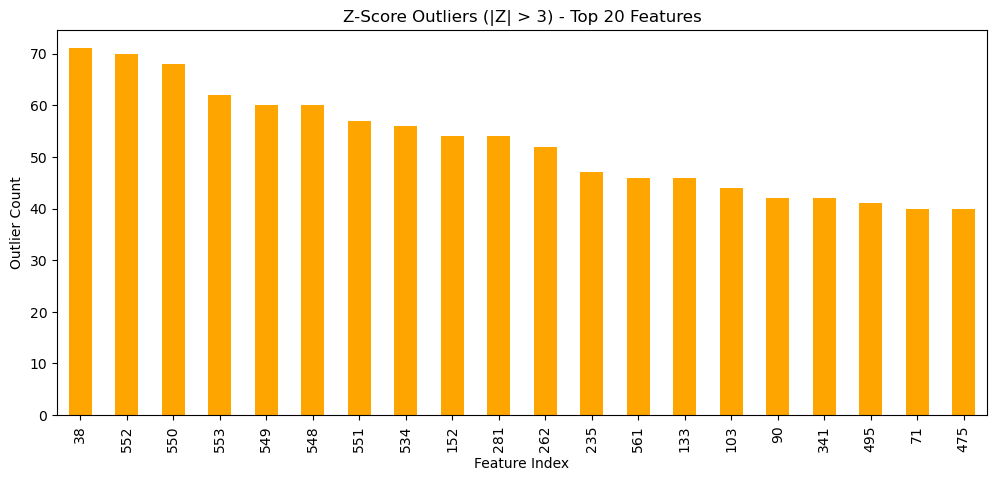

Total Z-Score Outliers: 6198


In [21]:
# Z-scores
z_scores = (X_df - X_df.mean()) / X_df.std()

z_outliers = np.abs(z_scores) > 3

zscore_count = z_outliers.sum().sum()

z_feature = z_outliers.sum().sort_values(ascending=False).head(20)

# Plot
plt.figure(figsize=(12,5))

z_feature.plot(kind='bar', color='orange')

plt.title("Z-Score Outliers (|Z| > 3) - Top 20 Features")
plt.xlabel("Feature Index")
plt.ylabel("Outlier Count")

plt.show()

print("Total Z-Score Outliers:", zscore_count)

In [22]:
comparison = pd.DataFrame({
    "Method": ["IQR", "Z-Score"],
    "Outlier Count": [iqr_count, zscore_count]
})

print("Outlier Detection Comparison:")
display(comparison)

Outlier Detection Comparison:


,Method,Outlier Count
0,IQR,26764
1,Z-Score,6198


## PCA

In [23]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [24]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("First 10 component variance ratios:")
print(explained_variance[:10])

First 10 component variance ratios:
[0.05728088 0.03856294 0.02988818 0.02676911 0.02193445 0.02079241
 0.01930091 0.01898798 0.01705595 0.01538383]


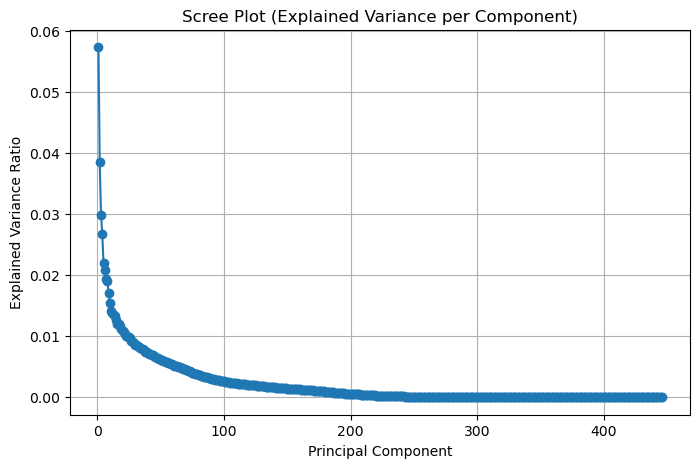

In [25]:
# Scree plot
plt.figure(figsize=(8,5))

plt.plot(range(1, len(explained_variance)+1),
         explained_variance, marker='o')

plt.title("Scree Plot (Explained Variance per Component)")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.grid()
plt.show()

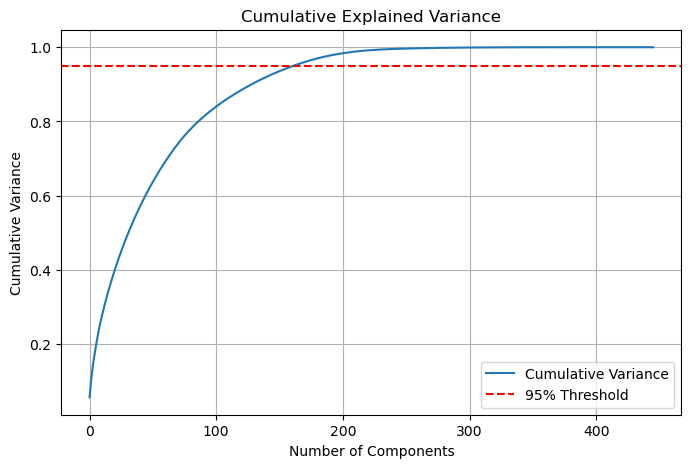

In [26]:
plt.figure(figsize=(8,5))

plt.plot(cumulative_variance, label="Cumulative Variance")
plt.axhline(y=0.95, color='red', linestyle='--', label="95% Threshold")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.title("Cumulative Explained Variance")

plt.legend()
plt.grid()
plt.show()

In [27]:
# components for 90% ,95% and 99% 
n_70 = np.argmax(cumulative_variance >= 0.70) + 1
n_80 = np.argmax(cumulative_variance >= 0.80) + 1
n_85 = np.argmax(cumulative_variance >= 0.85) + 1
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1
n_99 = np.argmax(cumulative_variance >= 0.99) + 1

print("Components needed for:")
print("70% variance :", n_70)
print("80% variance :", n_80)
print("85% variance :", n_85)
print("90% variance :", n_90)
print("95% variance :", n_95)
print("99% variance :", n_99)

Components needed for:
70% variance : 63
80% variance : 87
85% variance : 105
90% variance : 129
95% variance : 162
99% variance : 216


In [28]:
pca_final = PCA(n_components=n_95)
X_reduced = pca_final.fit_transform(X_scaled)
print("Dataset shape after PCA:", X_reduced.shape)

Dataset shape after PCA: (1567, 162)


## K - MEANS

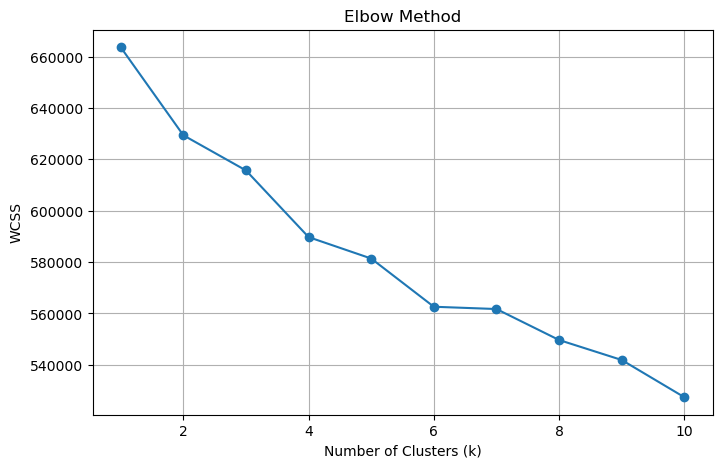

In [29]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_reduced)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")

plt.grid()
plt.show()

Best k from Silhouette Score: 2


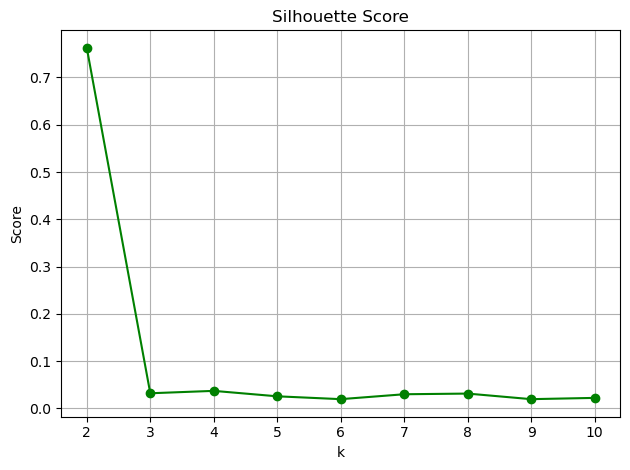

In [30]:
sil_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_reduced)
    
    score = silhouette_score(X_reduced, cluster_labels)
    sil_scores.append(score)

best_k = range(2, 11)[np.argmax(sil_scores)]
print("Best k from Silhouette Score:", best_k)

plt.plot(range(2, 11), sil_scores, marker='o', color='green', label="Silhouette Score")
plt.title("Silhouette Score")
plt.xlabel("k")
plt.ylabel("Score")
plt.grid()

plt.tight_layout()
plt.show()

In [31]:
k = 2  # chosen based on elbow and silhoutte method

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_reduced)

print("Number of clusters selected:", k)
print("Cluster labels:", np.unique(clusters))

Number of clusters selected: 2
Cluster labels: [0 1]


In [32]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()

print("Cluster distribution:")
print(cluster_counts)

Cluster distribution:
0    1563
1       4
Name: count, dtype: int64


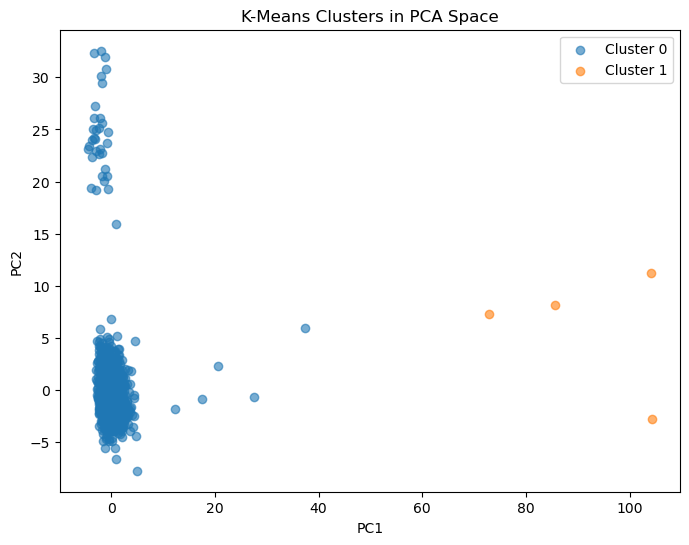


Cluster vs True Label:
True Label    -1    1
Cluster              
0           1460  103
1              3    1


In [33]:
plt.figure(figsize=(8,6))

for label in np.unique(clusters):
    plt.scatter(
        X_reduced[clusters == label, 0],
        X_reduced[clusters == label, 1],
        label=f"Cluster {label}",
        alpha=0.6
    )

plt.title("K-Means Clusters in PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

print("\nCluster vs True Label:")
print(pd.crosstab(clusters, y, rownames=['Cluster'], colnames=['True Label']))

## Classifiers

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (1253, 162)
Test shape: (314, 162)


## KNN

In [35]:
#k - Comparison
k_values = [2, 3, 4, 5,6]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred_knn = knn.predict(X_test)

    print(f"\nResults for k = {k}")
    print("Accuracy:", accuracy_score(y_test, y_pred_knn))
    print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))
    print("F1-score:", f1_score(y_test, y_pred_knn, zero_division=0))


Results for k = 2
Accuracy: 0.9394904458598726
Precision: 0.75
Recall: 0.14285714285714285
F1-score: 0.24

Results for k = 3
Accuracy: 0.9426751592356688
Precision: 0.8
Recall: 0.19047619047619047
F1-score: 0.3076923076923077

Results for k = 4
Accuracy: 0.9363057324840764
Precision: 1.0
Recall: 0.047619047619047616
F1-score: 0.09090909090909091

Results for k = 5
Accuracy: 0.9331210191082803
Precision: 0.5
Recall: 0.047619047619047616
F1-score: 0.08695652173913043

Results for k = 6
Accuracy: 0.9331210191082803
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [36]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

knn_acc = accuracy_score(y_test, y_pred_knn)

print("k-NN Accuracy:", knn_acc)

k-NN Accuracy: 0.9331210191082803


## Decision Tree

In [37]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

dt_acc = accuracy_score(y_test, y_pred_dt)

print("Baseline Decision Tree")
print("Decision Tree Accuracy:", dt_acc)
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_dt, zero_division=0))

Baseline Decision Tree
Decision Tree Accuracy: 0.8726114649681529
Precision: 0.047619047619047616
Recall: 0.047619047619047616
F1-score: 0.047619047619047616


In [38]:
depth_values = [3, 5, 10, 15, 20, None]

for depth in depth_values:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)

    y_pred = dt.predict(X_test)

    print(f"\nDepth = {depth}")
    print("F1:", f1_score(y_test, y_pred, zero_division=0))


Depth = 3
F1: 0.0

Depth = 5
F1: 0.0

Depth = 10
F1: 0.0

Depth = 15
F1: 0.0

Depth = 20
F1: 0.058823529411764705

Depth = None
F1: 0.047619047619047616


In [39]:
dt_balanced = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

dt_balanced.fit(X_train, y_train)
y_pred_dt = dt_balanced.predict(X_test)

dt_balanced_acc = accuracy_score(y_test, y_pred_dt)

print("Final Model (Balanced Decision Tree)")
print("Accuracy:", dt_balanced_acc)
print("Precision:", precision_score(y_test, y_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_dt, zero_division=0))

Final Model (Balanced Decision Tree)
Accuracy: 0.8089171974522293
Precision: 0.024390243902439025
Recall: 0.047619047619047616
F1-score: 0.03225806451612903


## SVM Classifier

In [40]:
#for complex boundaries we are using rbf kernel

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

svm_acc = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_acc)

SVM Accuracy: 0.9331210191082803


In [41]:
results = pd.DataFrame({
    "Model": ["k-NN", "Balanced Decision Tree", "SVM"],
    "Accuracy": [knn_acc, dt_balanced_acc, svm_acc]
})

display(results)

,Model,Accuracy
0,k-NN,0.933121
1,Balanced Decision Tree,0.808917
2,SVM,0.933121


In [42]:
best_model = results.loc[results["Accuracy"].idxmax()]

print("Best Model:", best_model["Model"])
print("Best Accuracy:", best_model["Accuracy"])

Best Model: k-NN
Best Accuracy: 0.9331210191082803


## SMOTE

In [43]:
smote = SMOTE(random_state=42)

X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", X_train.shape, y_train.value_counts())
print("After SMOTE:", X_train_sm.shape, y_train_sm.value_counts())

Before SMOTE: (1253, 162) 0
-1    1170
 1      83
Name: count, dtype: int64
After SMOTE: (2340, 162) 0
-1    1170
 1    1170
Name: count, dtype: int64


In [44]:
# Retraining models
# k-NN
knn_sm = KNeighborsClassifier(n_neighbors=5)
knn_sm.fit(X_train_sm, y_train_sm)
y_pred_knn_sm = knn_sm.predict(X_test)

# Decision Tree
dt_sm = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)
dt_sm.fit(X_train_sm, y_train_sm)
y_pred_dt_sm = dt_sm.predict(X_test)

# SVM
svm_sm = SVC(kernel='rbf', random_state=42)
svm_sm.fit(X_train_sm, y_train_sm)
y_pred_svm_sm = svm_sm.predict(X_test)

In [45]:
comparison = pd.DataFrame({
    "Model": ["k-NN", "Decision Tree", "SVM"],

    "Accuracy_Before": [
        knn_acc, dt_balanced_acc, svm_acc
    ],

    "Accuracy_After_SMOTE": [
        accuracy_score(y_test, y_pred_knn_sm),
        accuracy_score(y_test, y_pred_dt_sm),
        accuracy_score(y_test, y_pred_svm_sm)
    ]
})

display(comparison)

,Model,Accuracy_Before,Accuracy_After_SMOTE
0,k-NN,0.933121,0.366242
1,Decision Tree,0.808917,0.761146
2,SVM,0.933121,0.929936


## Model Evaluation

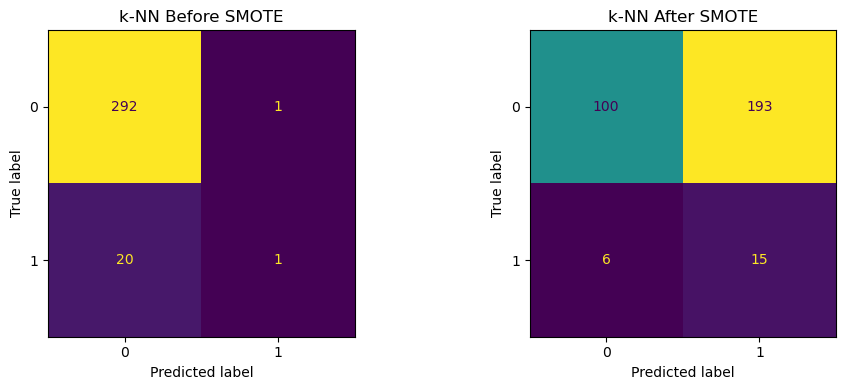

In [46]:
# K-NN
cm_before = confusion_matrix(y_test, y_pred_knn)
cm_after = confusion_matrix(y_test, y_pred_knn_sm)

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Before SMOTE
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_before)
disp1.plot(ax=axes[0], colorbar=False)
axes[0].set_title("k-NN Before SMOTE")

# After SMOTE
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_after)
disp2.plot(ax=axes[1], colorbar=False)
axes[1].set_title("k-NN After SMOTE")

plt.tight_layout()
plt.show()

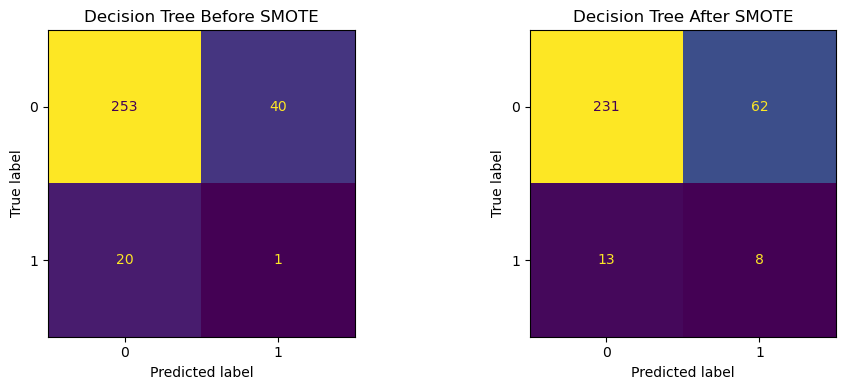

In [47]:
# Decision Tree
cm_dt_before = confusion_matrix(y_test, y_pred_dt)
cm_dt_after = confusion_matrix(y_test, y_pred_dt_sm)

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Before SMOTE
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_dt_before)
disp1.plot(ax=axes[0], colorbar=False)
axes[0].set_title("Decision Tree Before SMOTE")

# After SMOTE
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_dt_after)
disp2.plot(ax=axes[1], colorbar=False)
axes[1].set_title("Decision Tree After SMOTE")

plt.tight_layout()
plt.show()

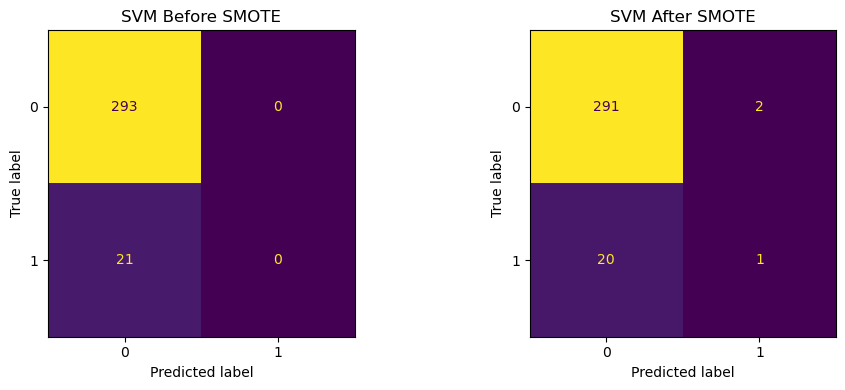

In [48]:
# SVM
cm_svm_before = confusion_matrix(y_test, y_pred_svm)
cm_svm_after = confusion_matrix(y_test, y_pred_svm_sm)

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Before SMOTE
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_svm_before)
disp1.plot(ax=axes[0], colorbar=False)
axes[0].set_title("SVM Before SMOTE")

# After SMOTE
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_svm_after)
disp2.plot(ax=axes[1], colorbar=False)
axes[1].set_title("SVM After SMOTE")

plt.tight_layout()
plt.show()

In [49]:
models = [
    ("k-NN", y_pred_knn, y_pred_knn_sm),
    ("Decision Tree", y_pred_dt, y_pred_dt_sm),
    ("SVM", y_pred_svm, y_pred_svm_sm)
]

before_results = []
after_results = []

for name, y_before, y_after in models:

    # BEFORE SMOTE
    before_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_before),
        "Precision": precision_score(y_test, y_before, zero_division=0),
        "Recall": recall_score(y_test, y_before, zero_division=0),
        "F1 Score": f1_score(y_test, y_before, zero_division=0)
    })

    # AFTER SMOTE
    after_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_after),
        "Precision": precision_score(y_test, y_after, zero_division=0),
        "Recall": recall_score(y_test, y_after, zero_division=0),
        "F1 Score": f1_score(y_test, y_after, zero_division=0)
    })

df_before = pd.DataFrame(before_results).set_index("Model")
df_after = pd.DataFrame(after_results).set_index("Model")

print("BEFORE SMOTE")
display(df_before.round(4))

print("\nAFTER SMOTE")
display(df_after.round(4))

BEFORE SMOTE


,Accuracy,Precision,Recall,F1 Score
Model,,,,
k-NN,0.9331,0.5000,0.0476,0.0870
Decision Tree,0.8089,0.0244,0.0476,0.0323
SVM,0.9331,0.0000,0.0000,0.0000



AFTER SMOTE


,Accuracy,Precision,Recall,F1 Score
Model,,,,
k-NN,0.3662,0.0721,0.7143,0.1310
Decision Tree,0.7611,0.1143,0.3810,0.1758
SVM,0.9299,0.3333,0.0476,0.0833
